# Importação de Bibliotecas

In [2]:
# Importação framework para análise de dados
import pandas as pd
# Importação framework para operações matemáticas
import math
import numpy as np
# Importação framework para visualização de dados
import matplotlib.pyplot as plt
# Importação framework para visualização de dados
import seaborn as sns
# Importação framework para métricas de avaliação
from sklearn.metrics import confusion_matrix

# Tratamento de Dados

In [3]:
df = pd.read_csv(f'../Data/stm32report/models_results.csv', header=None, names=['index_execucao', 'modelo', 'ciclos', 'tempo_execucao', 'decisao'])
df['index_execucao'] = df['index_execucao'].str.replace('[', '').str.replace(']', '').astype(int)
df['modelo'] = df['modelo'].str.replace(' ', '')
df['ciclos'] = df['ciclos'].str.replace(' ciclos', '').astype(int)
df['tempo_execucao'] = df['tempo_execucao'].str.replace(' us', '').astype(int)
df['decisao'] = df['decisao'].str.replace(' decisao', '').astype(int)
df.head(9)

,index_execucao,modelo,ciclos,tempo_execucao,decisao
0,1,Fuzzy,13096,204,1
1,1,Logistica,5937,92,1
2,1,SVM,169715,2651,1
3,1,ArvoreDecisao,994,15,1
4,1,LGB,29546,461,1
5,1,RFR,18125,283,1
6,1,QDA,11030,172,1
7,1,NNW,18613,290,1
8,1,KNN,45434,709,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2700 entries, 0 to 2699
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   index_execucao  2700 non-null   int64
 1   modelo          2700 non-null   str  
 2   ciclos          2700 non-null   int64
 3   tempo_execucao  2700 non-null   int64
 4   decisao         2700 non-null   int64
dtypes: int64(4), str(1)
memory usage: 105.6 KB


# Análise de Resultados

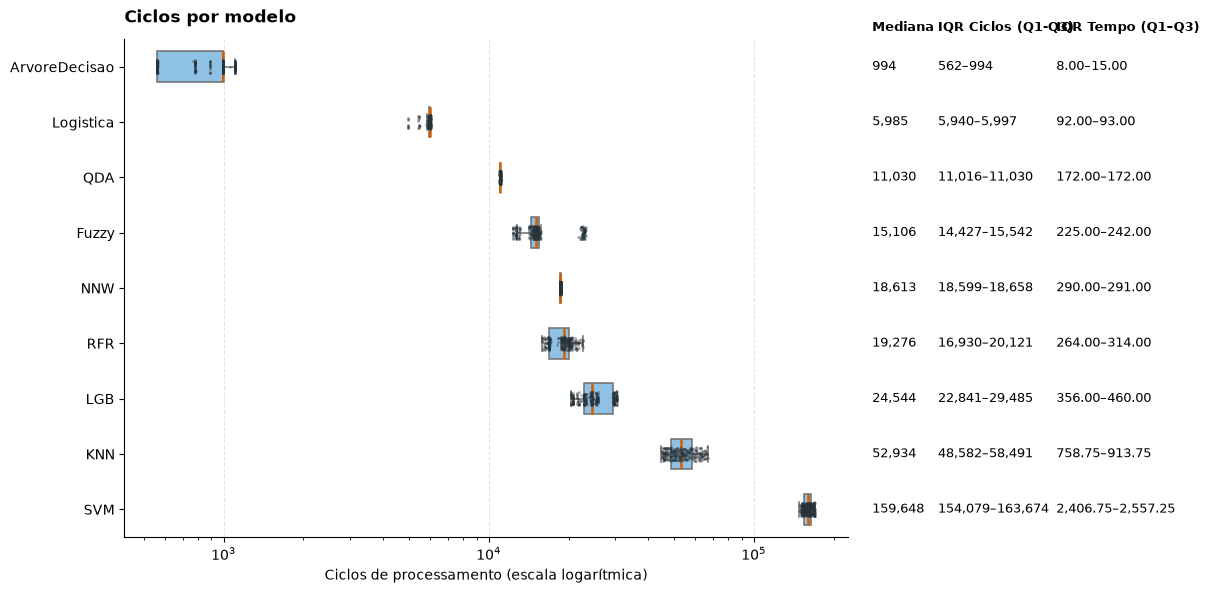

In [5]:
sub = df.copy()
sub["index_execucao"] = pd.to_numeric(sub["index_execucao"], errors="coerce")
sub["ciclos"] = pd.to_numeric(sub["ciclos"], errors="coerce")
sub["tempo_execucao"] = pd.to_numeric(sub["tempo_execucao"], errors="coerce")
sub = sub.dropna(subset=["index_execucao", "ciclos", "modelo", "tempo_execucao"])

ordem = (
    sub.groupby("modelo")["ciclos"]
       .median()
       .sort_values()
       .index
)

resumo = sub.groupby("modelo").agg(
    n=("ciclos", "size"),
    mediana=("ciclos", "median"),
    q1=("ciclos", lambda valores: valores.quantile(0.25)),
    q3=("ciclos", lambda valores: valores.quantile(0.75)),
    tempo_q1=("tempo_execucao", lambda valores: valores.quantile(0.25)),
    tempo_q3=("tempo_execucao", lambda valores: valores.quantile(0.75)),
).reindex(ordem)

fig = plt.figure(figsize=(12, max(4.5, 0.48 * len(ordem) + 1.5)), layout="constrained")
grid = fig.add_gridspec(1, 2, width_ratios=(5.5, 2.5), wspace=0.03)
ax = fig.add_subplot(grid[0, 0])
ax_resumo = fig.add_subplot(grid[0, 1], sharey=ax)

sns.boxplot(
    data=sub, x="ciclos", y="modelo",
    order=ordem, showfliers=False, width=0.55,
    color="#81C3F2", linewidth=1.1,
    medianprops={"color": "#D55E00", "linewidth": 1.8},
    ax=ax,
)
sns.stripplot(
    data=sub, x="ciclos", y="modelo",
    order=ordem, jitter=0.12, alpha=0.4,
    size=2, color="#263238", ax=ax,
)

ax.set_xscale("log")
ax.set_title("Ciclos por modelo", loc="left", weight="bold", pad=12)
ax.set_xlabel("Ciclos de processamento (escala logarítmica)")
ax.set_ylabel("")
ax.grid(axis="x", which="major", linestyle="--", alpha=0.35)
ax.grid(axis="x", which="minor", visible=False)
ax.set_axisbelow(True)
sns.despine(ax=ax)

ax_resumo.set_xlim(0, 1)
ax_resumo.set_ylim(ax.get_ylim())
ax_resumo.set_axis_off()

for x, titulo in ((0.02, "Mediana"), (0.22, "IQR Ciclos (Q1-Q3)"), (0.58, "IQR Tempo (Q1–Q3)")):
    ax_resumo.text(x, 1.01, titulo, transform=ax_resumo.transAxes,
                   ha="left", va="bottom", weight="bold", fontsize=9)
for pos, modelo in enumerate(ordem):
    linha = resumo.loc[modelo]
    iqr = f"{linha['q1']:,.0f}–{linha['q3']:,.0f}"
    iqr_tempo = f"{linha['tempo_q1']:,.2f}–{linha['tempo_q3']:,.2f}"
    ax_resumo.text(0.02, pos, f"{linha['mediana']:,.0f}", ha="left", va="center", fontsize=9)
    ax_resumo.text(0.22, pos, iqr, ha="left", va="center", fontsize=9)
    ax_resumo.text(0.58, pos, iqr_tempo, ha="left", va="center", fontsize=9)

plt.show()

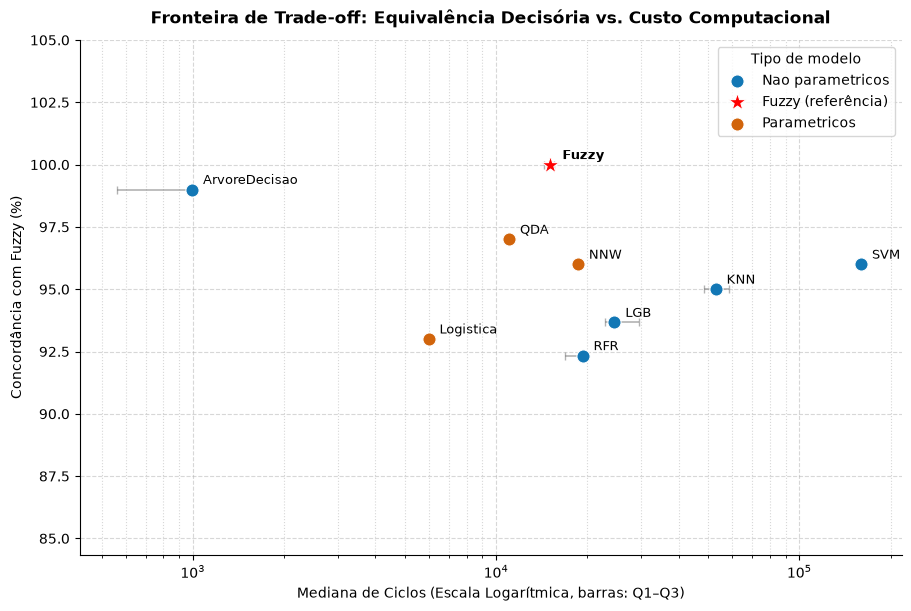

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

modelo_base = "Fuzzy"
grupos_modelos = {
    "Parametricos": ["Logistica", "QDA", "NNW"],
    "Nao parametricos": ["SVM", "ArvoreDecisao", "LGB", "RFR", "KNN"],
}
cores_grupos = {
    "Parametricos": "#D1640B",
    "Nao parametricos": "#1277B5",
}
grupo_por_modelo = {
    modelo: grupo
    for grupo, modelos in grupos_modelos.items()
    for modelo in modelos
}

# 1. Limpeza dos dados
df_clean = sub.dropna(subset=["index_execucao", "modelo", "ciclos", "decisao"]).copy()
df_clean["ciclos"] = pd.to_numeric(df_clean["ciclos"], errors="coerce")
df_clean["decisao"] = pd.to_numeric(df_clean["decisao"], errors="coerce")

# 2. Pivotar para calcular a concordância pareada com o modelo base
pivot_decisoes = df_clean.pivot_table(
    index="index_execucao",
    columns="modelo",
    values="decisao",
    aggfunc="first"
)

# 3. Métricas de custo (Ciclos: Q1, Mediana, Q3) e Concordância
estatisticas = []

for modelo in pivot_decisoes.columns:
    dados_modelo = df_clean[df_clean["modelo"] == modelo]["ciclos"].dropna()
    
    mediana_ciclos = dados_modelo.median()
    q1_ciclos = dados_modelo.quantile(0.25)
    q3_ciclos = dados_modelo.quantile(0.75)
    
    if modelo == modelo_base:
        concordancia = 100.0
    else:
        validos = pivot_decisoes[[modelo_base, modelo]].dropna()
        concordancia = (validos[modelo_base] == validos[modelo]).mean() * 100.0 if len(validos) > 0 else np.nan
        
    estatisticas.append({
        "modelo": modelo,
        "mediana_ciclos": mediana_ciclos,
        "q1_ciclos": q1_ciclos,
        "q3_ciclos": q3_ciclos,
        "concordancia": concordancia
    })

df_pareto = pd.DataFrame(estatisticas).dropna(subset=["concordancia", "mediana_ciclos"])
modelos_sem_grupo = sorted(
    set(df_pareto["modelo"]) - {modelo_base} - set(grupo_por_modelo)
)
if modelos_sem_grupo:
    raise ValueError(f"Modelos sem grupo definido: {modelos_sem_grupo}")

# 4. Plotagem
fig, ax = plt.subplots(figsize=(9, 6), layout="constrained")
rotulos_legenda_exibidos = set()

for _, linha in df_pareto.iterrows():
    mod = linha["modelo"]
    x = linha["mediana_ciclos"]
    y = linha["concordancia"]
    x_err_min = x - linha["q1_ciclos"]
    x_err_max = linha["q3_ciclos"] - x
    
    eh_base = (mod == modelo_base)
    if eh_base:
        cor = "#FF0000"
        rotulo = "Fuzzy (referência)"
        marcador = "*"
        tamanho = 180
    else:
        grupo = grupo_por_modelo[mod]
        cor = cores_grupos[grupo]
        rotulo = grupo if grupo not in rotulos_legenda_exibidos else "_nolegend_"
        marcador = "o"
        tamanho = 90
    
    # Barra de erro horizontal representando o intervalo [Q1, Q3]
    ax.errorbar(
        x, y, 
        xerr=[[x_err_min], [x_err_max]], 
        fmt="none", 
        ecolor="gray", 
        elinewidth=1.2, 
        capsize=3, 
        alpha=0.6, 
        zorder=2
    )
    
    # Ponto central (Mediana)
    ax.scatter(x, y, color=cor, marker=marcador, s=tamanho, zorder=3, edgecolors="white", linewidth=0.8, label=rotulo)
    if rotulo != "_nolegend_":
        rotulos_legenda_exibidos.add(rotulo)
    
    # Rótulo de texto do modelo
    ax.annotate(
        f" {mod}", 
        (x, y), 
        xytext=(5, 4), 
        textcoords="offset points", 
        fontsize=9, 
        weight="bold" if eh_base else "normal"
    )

ax.set_xscale("log")
ax.set_ylim(max(0, df_pareto["concordancia"].min() - 8), 105)

ax.set_title("Fronteira de Trade-off: Equivalência Decisória vs. Custo Computacional", weight="bold", pad=12, loc="center")
ax.set_xlabel("Mediana de Ciclos (Escala Logarítmica, barras: Q1–Q3)", fontsize=10)
ax.set_ylabel(f"Concordância com {modelo_base} (%)", fontsize=10)
ax.legend(title="Tipo de modelo")

ax.grid(True, which="major", linestyle="--", alpha=0.5)
ax.grid(True, which="minor", linestyle=":", alpha=0.5)
ax.set_axisbelow(True)
sns.despine(ax=ax)

plt.show()

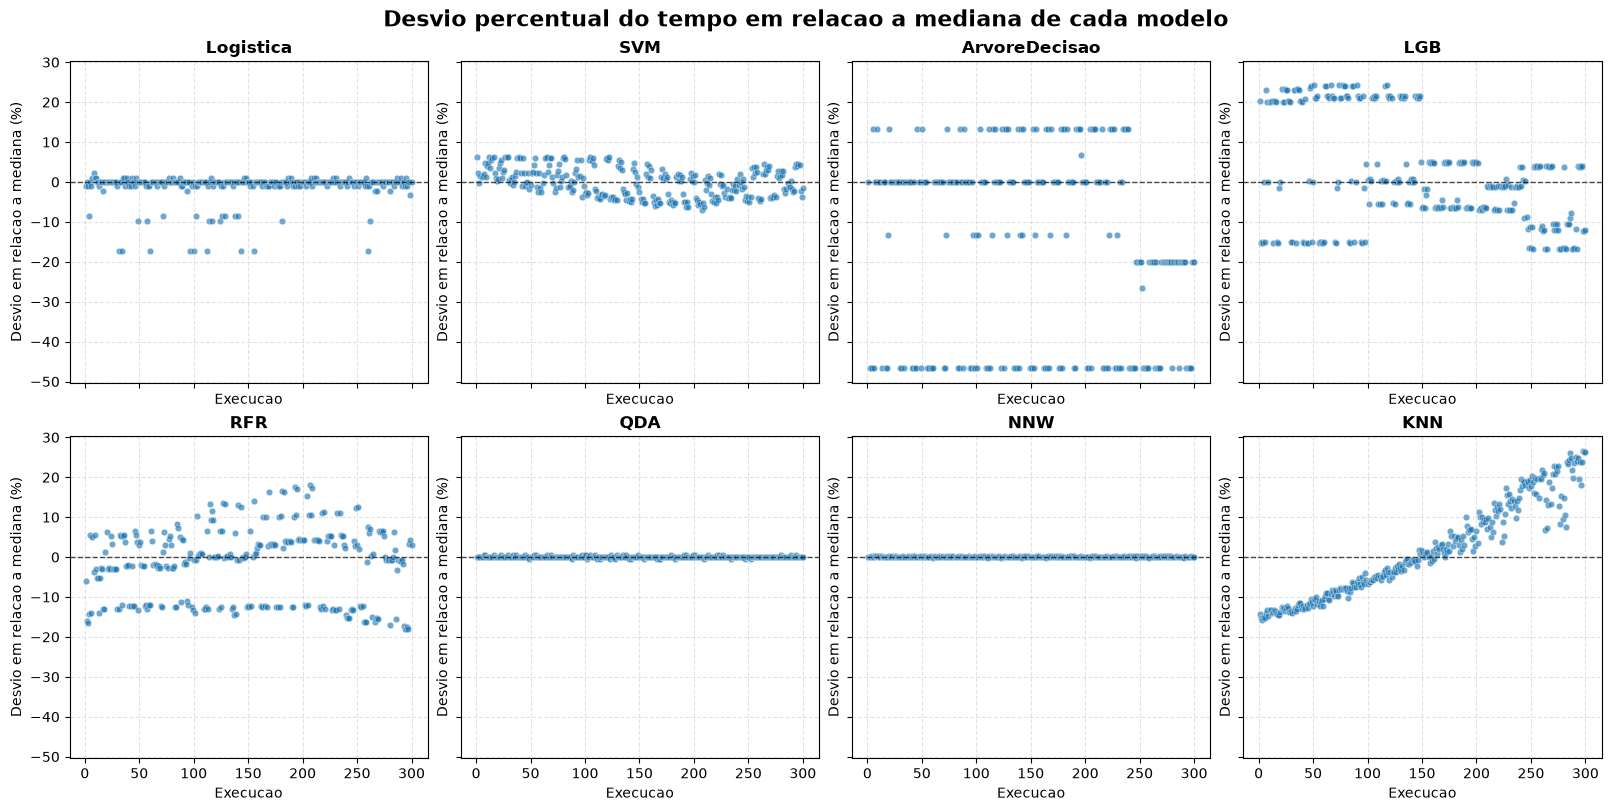

In [7]:
# Comparacao dos oito modelos de ML; referencia Fuzzy fora da grade.
modelos = [modelo for modelo in df['modelo'].dropna().unique() if modelo != 'Fuzzy']

fig, axes = plt.subplots(2, 4, figsize=(16, 8), sharex=True, sharey=True, constrained_layout=True)
axes = axes.ravel()

for ax, modelo in zip(axes, modelos):
    dados_modelo = df.loc[df['modelo'] == modelo]
    mediana_tempo = dados_modelo['tempo_execucao'].median()
    desvio_percentual = (dados_modelo['tempo_execucao'] - mediana_tempo) / mediana_tempo * 100
    ax.scatter(
        dados_modelo['index_execucao'],
        desvio_percentual,
        color='tab:blue',
        alpha=0.65,
        s=22,
        edgecolors='white',
        linewidths=0.35
    )
    ax.set_title(modelo, fontsize=12, fontweight='bold')
    ax.set_xlabel('Execucao')
    ax.set_ylabel('Desvio em relacao a mediana (%)')
    ax.axhline(0, color='black', linewidth=1, linestyle='--', alpha=0.7)
    ax.grid(True, linestyle='--', alpha=0.35)

fig.suptitle('Desvio percentual do tempo em relacao a mediana de cada modelo', fontsize=16, fontweight='bold')
plt.show()

In [8]:
# As metricas expressam concordancia com Fuzzy, que e referencia, nao rotulo real independente.
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from IPython.display import display

modelo_base = 'Fuzzy'
grupos_modelos = {
    'Parametricos': ['Logistica', 'QDA', 'NNW'],
    'Nao parametricos': ['SVM', 'ArvoreDecisao', 'LGB', 'RFR', 'KNN'],
}
pivot_decisoes = df.pivot_table(
    index='index_execucao',
    columns='modelo',
    values='decisao',
    aggfunc='first'
)

if modelo_base not in pivot_decisoes.columns:
    raise ValueError(f"Modelo de referencia ausente: {modelo_base}")

modelos_avaliados = [modelo for modelo in pivot_decisoes.columns if modelo != modelo_base]
modelos_classificados = [modelo for grupo in grupos_modelos.values() for modelo in grupo]
modelos_nao_classificados = sorted(set(modelos_avaliados) - set(modelos_classificados))
modelos_ausentes = sorted(set(modelos_classificados) - set(modelos_avaliados))
if modelos_nao_classificados or modelos_ausentes:
    raise ValueError(
        f"Revise os grupos de modelos. Sem classificacao: {modelos_nao_classificados}; "
        f"ausentes nos dados: {modelos_ausentes}"
    )

modelos_parametricos = grupos_modelos['Parametricos']
modelos_nao_parametricos = grupos_modelos['Nao parametricos']

def calcular_metricas(y_real, y_predito):
    matriz = confusion_matrix(y_real, y_predito, labels=[0, 1])
    verdadeiros_negativos, falsos_positivos, falsos_negativos, verdadeiros_positivos = matriz.ravel()
    especificidade = (
        verdadeiros_negativos / (verdadeiros_negativos + falsos_positivos)
        if verdadeiros_negativos + falsos_positivos else np.nan
    )
    metricas = {
        'N': len(y_real),
        'Acuracia': accuracy_score(y_real, y_predito),
        'Precisao': precision_score(y_real, y_predito, pos_label=1, zero_division=0),
        'Recall': recall_score(y_real, y_predito, pos_label=1, zero_division=0),
        'Especificidade': especificidade,
        'F1-score': f1_score(y_real, y_predito, pos_label=1, zero_division=0),
    }
    return metricas, matriz

resultados_metricas = []
matrizes_confusao = {}
for grupo, modelos_grupo in grupos_modelos.items():
    for modelo in modelos_grupo:
        pares_validos = pivot_decisoes[[modelo_base, modelo]].dropna()
        y_real = pares_validos[modelo_base].astype(int)
        y_predito = pares_validos[modelo].astype(int)
        metricas, matrizes_confusao[modelo] = calcular_metricas(y_real, y_predito)
        resultados_metricas.append({'Grupo': grupo, 'Modelo': modelo, **metricas})

df_metricas = pd.DataFrame(resultados_metricas).set_index(['Grupo', 'Modelo'])
display(df_metricas.style.format('{:.3f}', subset=['Acuracia', 'Precisao', 'Recall', 'Especificidade', 'F1-score']))

# O voto majoritario resume cada familia em uma decisao por execucao.
resultados_metricas_grupo = []
matrizes_confusao_grupo = {}
for grupo, modelos_grupo in grupos_modelos.items():
    colunas = [modelo_base, *modelos_grupo]
    pares_validos = pivot_decisoes[colunas].dropna()
    y_real = pares_validos[modelo_base].astype(int)
    votos = pares_validos[modelos_grupo].astype(int)
    y_predito = (votos.sum(axis=1) > len(modelos_grupo) / 2).astype(int)
    metricas, matrizes_confusao_grupo[grupo] = calcular_metricas(y_real, y_predito)
    resultados_metricas_grupo.append({'Grupo': grupo, **metricas})

df_metricas_grupo = pd.DataFrame(resultados_metricas_grupo).set_index('Grupo')
display(df_metricas_grupo.style.format('{:.3f}', subset=['Acuracia', 'Precisao', 'Recall', 'Especificidade', 'F1-score']))

limite_cor = max(matriz.max() for matriz in matrizes_confusao.values())

def exibir_matrizes(modelos_grupo, cmap, titulo):
    n_colunas = min(3, len(modelos_grupo))
    n_linhas = int(np.ceil(len(modelos_grupo) / n_colunas))
    fig, axes = plt.subplots(
        n_linhas,
        n_colunas,
        figsize=(5 * n_colunas, 4.5 * n_linhas),
        squeeze=False,
        constrained_layout=True
    )

    for ax, modelo in zip(axes.ravel(), modelos_grupo):
        sns.heatmap(
            matrizes_confusao[modelo],
            annot=True,
            fmt='d',
            cmap=cmap,
            cbar=False,
            vmin=0,
            vmax=limite_cor,
            xticklabels=[0, 1],
            yticklabels=[0, 1],
            ax=ax
        )
        ax.set_title(modelo, fontweight='bold')
        ax.set_xlabel('Decisao do modelo')
        ax.set_ylabel('Decisao de referencia (Fuzzy)')

    for ax in axes.ravel()[len(modelos_grupo):]:
        ax.set_visible(False)

    fig.suptitle(titulo, fontsize=15, fontweight='bold')
    plt.show()

,N,Acuracia,Precisao,Recall,Especificidade,F1-score
Grupo,,,,,,
Parametricos,300,0.960,0.946,0.981,0.935,0.963
Nao parametricos,300,0.963,0.946,0.988,0.935,0.967


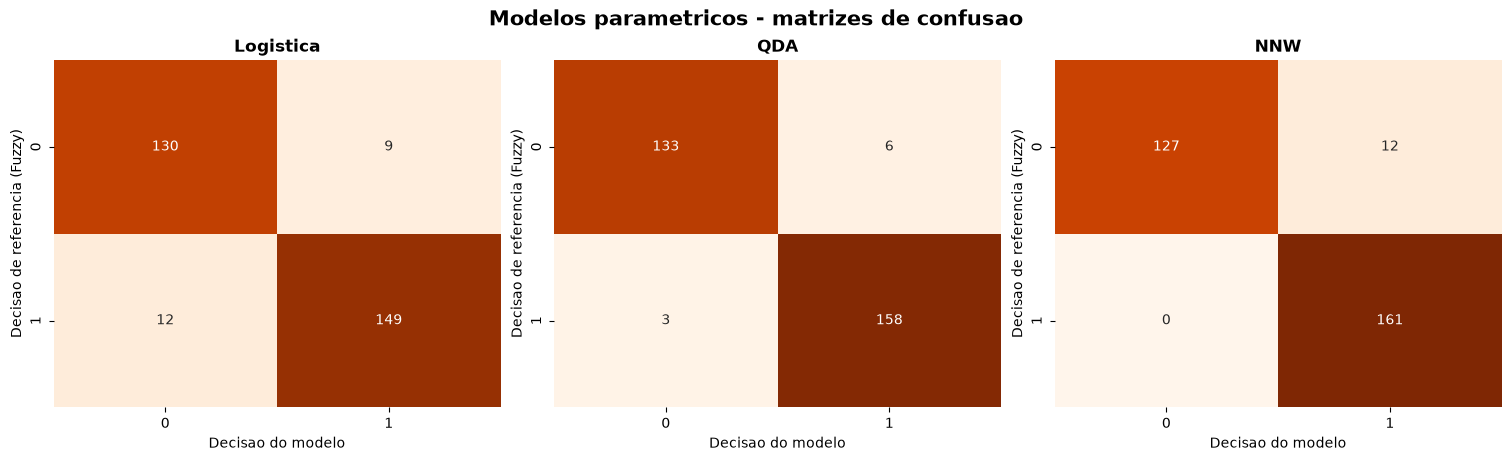

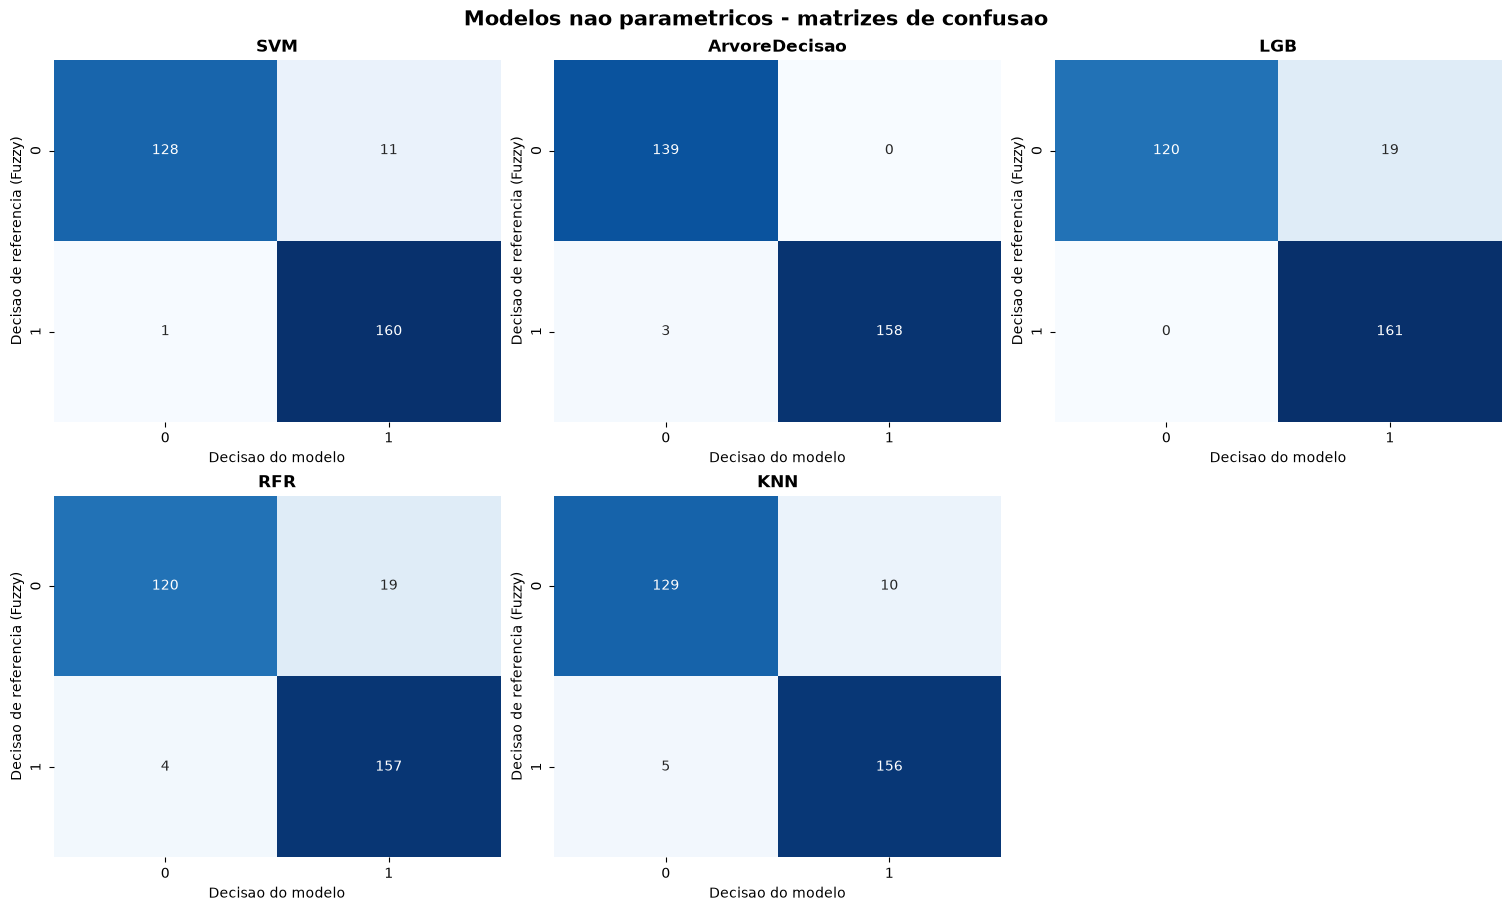

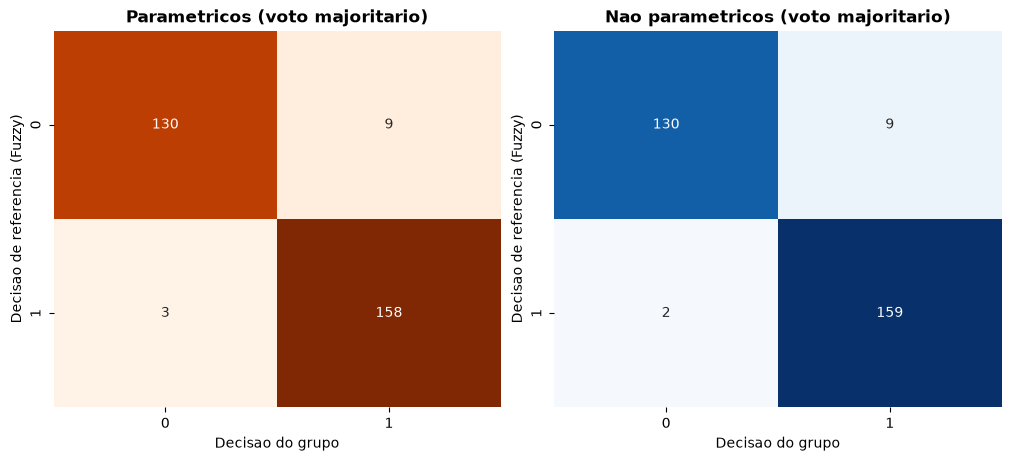

In [9]:
exibir_matrizes(modelos_parametricos, 'Oranges', 'Modelos parametricos - matrizes de confusao')
exibir_matrizes(modelos_nao_parametricos, 'Blues', 'Modelos nao parametricos - matrizes de confusao')

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), constrained_layout=True)
if 'matrizes_confusao_grupo' not in globals():
    grupos_modelos = {
        'Parametricos': modelos_parametricos,
        'Nao parametricos': modelos_nao_parametricos,
    }
    matrizes_confusao_grupo = {}
    for grupo, modelos_grupo in grupos_modelos.items():
        pares_validos = pivot_decisoes[[modelo_base, *modelos_grupo]].dropna()
        y_real = pares_validos[modelo_base].astype(int)
        votos = pares_validos[modelos_grupo].astype(int)
        y_predito = (votos.sum(axis=1) > len(modelos_grupo) / 2).astype(int)
        matrizes_confusao_grupo[grupo] = confusion_matrix(y_real, y_predito, labels=[0, 1])

limite_cor_grupo = max(matriz.max() for matriz in matrizes_confusao_grupo.values())
for ax, grupo, cmap in zip(axes, grupos_modelos, ['Oranges', 'Blues']):
    sns.heatmap(
        matrizes_confusao_grupo[grupo],
        annot=True,
        fmt='d',
        cmap=cmap,
        cbar=False,
        vmin=0,
        vmax=limite_cor_grupo,
        xticklabels=[0, 1],
        yticklabels=[0, 1],
        ax=ax
    )
    ax.set_title(f'{grupo} (voto majoritario)', fontweight='bold')
    ax.set_xlabel('Decisao do grupo')
    ax.set_ylabel('Decisao de referencia (Fuzzy)')
plt.show()